# Data Management

In [ ]:
import sys, os
import pandas as pd
from google.colab import drive
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def asteriskscheck(pval):
    if pval<=0.0001:
        asterisks="****"
    elif pval<=0.001:
        asterisks="***"
    elif pval<=0.01:
        asterisks="**"
    elif pval<=0.05:
        asterisks="*"
    else:
        asterisks="n.s."
    return asterisks

drive.mount('/content/drive')

#@markdown ## Enter path to drive folder containing tracks csvs
path_to_exp = "/content/drive/MyDrive/SCALPOL/Laboratory/Data Analysis/StarDist Stuff/48 Well Experiment TIF/New New New New New Tracking Results/Tracks" #@param{type:"string"}

groups = [] # List to collect well numbers for each group

#@markdown ## Enter well numbers for each treatment group as 01, 02, ...
#@markdown ### Group 1 (control)

group_1 = "01, 16, 17, 32, 33, 48" # @param {"type":"string"}
groups.append(group_1)

#@markdown ### Group 2
group_2 = "02, 15, 18, 31, 34, 47" # @param {"type":"string"}
groups.append(group_2)

#@markdown ### Group 3
group_3 = "03, 14, 19, 30, 35, 46" # @param {"type":"string"}
groups.append(group_3)

#@markdown ### Group 4
group_4 = "04, 13, 20, 29, 36, 45" # @param {"type":"string"}
groups.append(group_4)

#@markdown ### Group 5 (control 2)
group_5 = "05, 12, 21, 28, 37, 44" # @param {"type":"string"}
groups.append(group_5)

#@markdown ### Group 6
group_6 = "06, 11, 22, 27, 38, 43" # @param {"type":"string"}
groups.append(group_6)

#@markdown ### Group 7
group_7 = "07, 10, 23, 26, 39, 42" # @param {"type":"string"}
groups.append(group_7)

#@markdown ### Group 8
group_8 = "08, 09, 24, 25, 40, 41" # @param {"type":"string"}
groups.append(group_8)

for group in groups:  group = group.split(", ")

Mounted at /content/drive


In [ ]:
# Filter csvs on 'track_duration' column
csv_groups = [[], [], [], [], [], [], [], []]

# Add each csv in data folder to appropriate treatment group
with os.scandir(path_to_exp) as folder:
  for file in folder:

    well_number = file.name[-13:-11]

    if well_number in group_1:
      csv_groups[0].append(path_to_exp + '/' + file.name)
    elif well_number in group_2:
      csv_groups[1].append(path_to_exp + '/' + file.name)
    elif well_number in group_3:
      csv_groups[2].append(path_to_exp + '/' + file.name)
    elif well_number in group_4:
      csv_groups[3].append(path_to_exp + '/' + file.name)
    elif well_number in group_5:
      csv_groups[4].append(path_to_exp + '/' + file.name)
    elif well_number in group_6:
      csv_groups[5].append(path_to_exp + '/' + file.name)
    elif well_number in group_7:
      csv_groups[6].append(path_to_exp + '/' + file.name)
    elif well_number in group_8:
      csv_groups[7].append(path_to_exp + '/' + file.name)

# Convert csv's to df's
# Filter out tracks less than 10 frames
# Concatenate df's in the same groups
# Print filtering statistics
dfs = []
for csv_group in csv_groups:
  group_df = pd.DataFrame()
  for csv in csv_group:
    file_df = pd.read_csv(csv)
    file_df.drop([0, 1, 2], inplace=True)
    total_rows = file_df.shape[0]
    print(f'Total rows: {total_rows}')
    filtered_df = file_df[file_df['TRACK_DURATION'].astype(float) >= 10.0]
    print(f'Dropped: {total_rows - filtered_df.shape[0]}')
    print(f'Remaining: {filtered_df.shape[0]}')
    print(f'Percent dropped: {(total_rows - filtered_df.shape[0]) / total_rows * 100}\n')
    group_df = pd.concat([group_df, filtered_df], ignore_index=True)
  dfs.append(group_df)

Total rows: 166
Dropped: 33
Remaining: 133
Percent dropped: 19.879518072289155

Total rows: 256
Dropped: 36
Remaining: 220
Percent dropped: 14.0625

Total rows: 134
Dropped: 30
Remaining: 104
Percent dropped: 22.388059701492537

Total rows: 256
Dropped: 32
Remaining: 224
Percent dropped: 12.5

Total rows: 369
Dropped: 34
Remaining: 335
Percent dropped: 9.214092140921409

Total rows: 436
Dropped: 45
Remaining: 391
Percent dropped: 10.321100917431194

Total rows: 144
Dropped: 20
Remaining: 124
Percent dropped: 13.88888888888889

Total rows: 270
Dropped: 35
Remaining: 235
Percent dropped: 12.962962962962962

Total rows: 354
Dropped: 22
Remaining: 332
Percent dropped: 6.214689265536723

Total rows: 263
Dropped: 32
Remaining: 231
Percent dropped: 12.167300380228136

Total rows: 210
Dropped: 17
Remaining: 193
Percent dropped: 8.095238095238095

Total rows: 132
Dropped: 19
Remaining: 113
Percent dropped: 14.393939393939394

Total rows: 220
Dropped: 44
Remaining: 176
Percent dropped: 20.0

Tot

In [ ]:
# Collect speed and persistence data for each group
# Convert speed from pixels/frame to microns/hour
# Filter outliers by 1.5xIQR rule
speed = []
persistence = []
for df in dfs:
	df['TRACK_MEAN_SPEED'] = df['TRACK_MEAN_SPEED'].astype(float) / 3.6887 / 0.25

	speed_q1 = df['TRACK_MEAN_SPEED'].astype(float).quantile(0.25)
	speed_q3 = df['TRACK_MEAN_SPEED'].astype(float).quantile(0.75)
	speed_iqr = speed_q3 - speed_q1

	speed_filter_df = df[df['TRACK_MEAN_SPEED'].astype(float) >= speed_q1 - 1.5*speed_iqr]
	speed_filter_df = speed_filter_df[speed_filter_df['TRACK_MEAN_SPEED'].astype(float) <= speed_q3 + 1.5*speed_iqr]
	group_speed = speed_filter_df['TRACK_MEAN_SPEED'].to_numpy().astype(float)
	speed.append(group_speed)

	pers_q1 = df['LINEARITY_OF_FORWARD_PROGRESSION'].astype(float).quantile(0.25)
	pers_q3 = df['LINEARITY_OF_FORWARD_PROGRESSION'].astype(float).quantile(0.75)
	pers_iqr = pers_q3 - pers_q1

	pers_filter_df = df[df['LINEARITY_OF_FORWARD_PROGRESSION'].astype(float) >= pers_q1 - 1.5*pers_iqr]
	pers_filter_df = pers_filter_df[pers_filter_df['LINEARITY_OF_FORWARD_PROGRESSION'].astype(float) <= pers_q3 + 1.5*pers_iqr]
	group_persistence = pers_filter_df['LINEARITY_OF_FORWARD_PROGRESSION'].to_numpy().astype(float)
	persistence.append(group_persistence)


# Controls

In [ ]:
# Convert control well csv's to df's
# Filter out tracks less than 10 frames
control_dfs = []
for i in [0, 4]:
  for csv in csv_groups[i]:
    well_df = pd.DataFrame()
    well_df = pd.read_csv(csv)
    well_df.drop([0, 1, 2], inplace=True)
    filtered_well = well_df[well_df['TRACK_DURATION'].astype(float) >= 10.0]
    control_dfs.append(filtered_well)

# Collect speed and persistence for control groups
# Convert speeds from pixels/frame to microns/hour
control_speed = []
control_persistence = []
group_num = 1

for df in control_dfs:
  df['TRACK_MEAN_SPEED'] = df['TRACK_MEAN_SPEED'].astype(float) / 3.6887 / 0.25

  speed_q1 = df['TRACK_MEAN_SPEED'].astype(float).quantile(0.25)
  speed_q3 = df['TRACK_MEAN_SPEED'].astype(float).quantile(0.75)
  speed_iqr = speed_q3 - speed_q1

  speed_filter_df = df[df['TRACK_MEAN_SPEED'].astype(float) >= speed_q1 - 1.5*speed_iqr]
  speed_filter_df = speed_filter_df[speed_filter_df['TRACK_MEAN_SPEED'].astype(float) <= speed_q3 + 1.5*speed_iqr]
  group_speed = speed_filter_df['TRACK_MEAN_SPEED'].to_numpy().astype(float)
  control_speed.append(group_speed)

  pers_q1 = df['LINEARITY_OF_FORWARD_PROGRESSION'].astype(float).quantile(0.25)
  pers_q3 = df['LINEARITY_OF_FORWARD_PROGRESSION'].astype(float).quantile(0.75)
  pers_iqr = pers_q3 - pers_q1

  pers_filter_df = df[df['LINEARITY_OF_FORWARD_PROGRESSION'].astype(float) >= pers_q1 - 1.5*pers_iqr]
  pers_filter_df = pers_filter_df[pers_filter_df['LINEARITY_OF_FORWARD_PROGRESSION'].astype(float) <= pers_q3 + 1.5*pers_iqr]
  group_persistence = pers_filter_df['LINEARITY_OF_FORWARD_PROGRESSION'].to_numpy().astype(float)
  control_persistence.append(group_persistence)

  avg_speed = np.mean(group_speed)
  avg_pers = np.mean(group_persistence)

  print(f'Group {group_num} average speed: {avg_speed}, average persistence: {avg_pers}')
  group_num += 1

Group 1 average speed: 11.36493102966253, average persistence: 0.27048895655481225
Group 2 average speed: 11.189773223932045, average persistence: 0.2539840900545587
Group 3 average speed: 11.115751501623297, average persistence: 0.26352295485940674
Group 4 average speed: 11.49865465216556, average persistence: 0.2633064048718165
Group 5 average speed: 11.511090964253912, average persistence: 0.26682693705229105
Group 6 average speed: 11.592002940724266, average persistence: 0.230150158824179
Group 7 average speed: 9.000949159657038, average persistence: 0.2471397405192639
Group 8 average speed: 8.86446715284144, average persistence: 0.23456190547119743
Group 9 average speed: 8.958106824440993, average persistence: 0.24145144728540804
Group 10 average speed: 8.877143580420514, average persistence: 0.24063733248874666
Group 11 average speed: 8.307581877154472, average persistence: 0.22900407219299254
Group 12 average speed: 9.518143982585777, average persistence: 0.24377201668017984


/tmp/ipykernel_1205/3274596322.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['TRACK_MEAN_SPEED'] = df['TRACK_MEAN_SPEED'].astype(float) / 3.6887 / 0.25


In [ ]:
# Pairwise ANOVA's for speed and persistence data of each MDA control well
print('MDA Control Speed:\n')
for i in range(int(len(control_speed) / 2)):
  for j in range(i+1, int(len(control_speed) / 2)):
    speed_stat, speed_p = stats.f_oneway(control_speed[i], control_speed[j])
    print(f'(Control {i+1}, control {j+1}), Speed: {speed_stat}, {speed_p}\n')

print('MDA Control Persistence:\n')
for i in range(int(len(control_persistence) / 2)):
  for j in range(i+1, int(len(control_persistence) / 2)):
    pers_stat, pers_p = stats.f_oneway(control_persistence[i], control_persistence[j])
    print(f'(Control {i+1}, control {j+1}), Persistence: {pers_stat}, {pers_p}\n')

MDA Control Speed:

(Control 1, control 2), Speed: 0.445509600620032, 0.5049239327694647

(Control 1, control 3), Speed: 0.6049413351889888, 0.4375123177816812

(Control 1, control 4), Speed: 0.25885252460535013, 0.6112405411838636

(Control 1, control 5), Speed: 0.42356300227014954, 0.5154952043080712

(Control 1, control 6), Speed: 1.0513293855716754, 0.30569200310013595

(Control 2, control 3), Speed: 0.07061549597237896, 0.7906143740244972

(Control 2, control 4), Speed: 1.9652106184328866, 0.16167522977929938

(Control 2, control 5), Speed: 2.967375704904271, 0.08552686556636988

(Control 2, control 6), Speed: 4.874737619203905, 0.02763137061986343

(Control 3, control 4), Speed: 1.8864472536327712, 0.1705799139159573

(Control 3, control 5), Speed: 2.727185847426473, 0.09938645018850933

(Control 3, control 6), Speed: 4.0296984031156144, 0.04526480998748354

(Control 4, control 5), Speed: 0.00441491802232013, 0.9470482113100146

(Control 4, control 6), Speed: 0.2604696596929101, 

In [ ]:
# Pairwise ANOVA's for speed and persistence data of each PANC control well
print('PANC Control Speed:\n')
for i in range(int(len(control_speed) / 2), len(control_speed)):
  for j in range(i+1, int(len(control_speed))):
    speed_stat, speed_p = stats.f_oneway(control_speed[i], control_speed[j])
    print(f'(Control {i+1-6}, control {j+1-6}), Speed: {speed_stat}, {speed_p}\n')

print('PANC Control Persistence:\n')
for i in range(int(len(control_persistence) / 2), len(control_persistence)):
  for j in range(i+1, int(len(control_persistence))):
    pers_stat, pers_p = stats.f_oneway(control_persistence[i], control_persistence[j])
    print(f'(Control {i+1-6}, control {j+1-6}), Persistence: {pers_stat}, {pers_p}\n')

PANC Control Speed:

(Control 1, control 2), Speed: 0.24537140710986136, 0.620737637829338

(Control 1, control 3), Speed: 0.03161520923992745, 0.8589601319263311

(Control 1, control 4), Speed: 0.36804832241666696, 0.5443829156035669

(Control 1, control 5), Speed: 8.317750521356876, 0.004153096754618745

(Control 1, control 6), Speed: 5.039968901058986, 0.02531603422504964

(Control 2, control 3), Speed: 0.11829119230203274, 0.7310933168728522

(Control 2, control 4), Speed: 0.0031911021906298152, 0.9549810456965202

(Control 2, control 5), Speed: 4.386713258798578, 0.03701372963766795

(Control 2, control 6), Speed: 6.538934190484082, 0.010984885306665703

(Control 3, control 4), Speed: 0.17367080272949442, 0.6770411554414693

(Control 3, control 5), Speed: 8.177897186009856, 0.004434930935068975

(Control 3, control 6), Speed: 6.648439645328564, 0.010220476689713556

(Control 4, control 5), Speed: 8.572443878397124, 0.0035771190938870437

(Control 4, control 6), Speed: 11.836075390

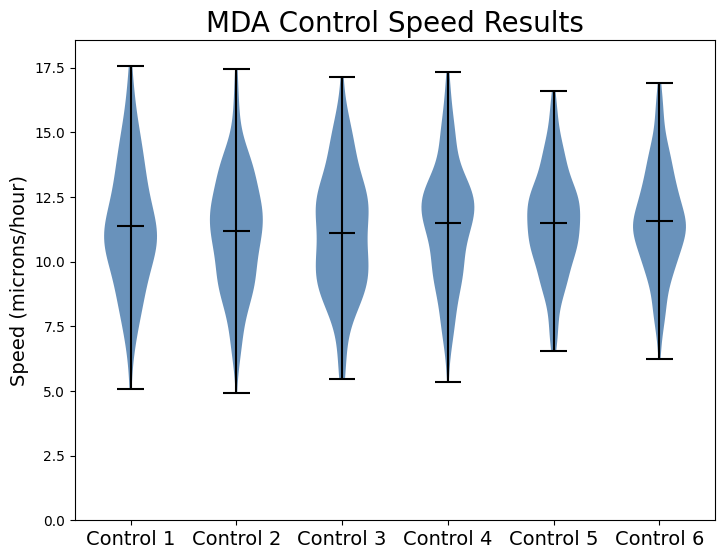

In [ ]:
# Violin plot of MDA control speeds
MDA_speed_controls = (control_speed[0], control_speed[1], control_speed[2],
                      control_speed[3], control_speed[4], control_speed[5])
fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xticks([1, 2, 3, 4, 5, 6])
ax.set_xticklabels(['Control 1', 'Control 2', 'Control 3', 'Control 4', 'Control 5', 'Control 6'], fontsize=14)
ax.set_ylim([0, np.max(np.concatenate(MDA_speed_controls)) + 1])
plt.ylabel('Speed (microns/hour)', fontsize=14)
vp = ax.violinplot([control_speed[0], control_speed[1], control_speed[2],
                    control_speed[3], control_speed[4], control_speed[5]],
                    showmeans=True, orientation='vertical')

vp['cbars'].set_color('black')
vp['cmeans'].set_color('black')
vp['cmaxes'].set_color('black')
vp['cmins'].set_color('black')

for i in range(6):
  vp['bodies'][i].set_facecolor((68/255.0, 119/255.0, 170/255.0))
  vp['bodies'][i].set_alpha(0.8)

plt.title('MDA Control Speed Results', fontsize=20)

plt.show()

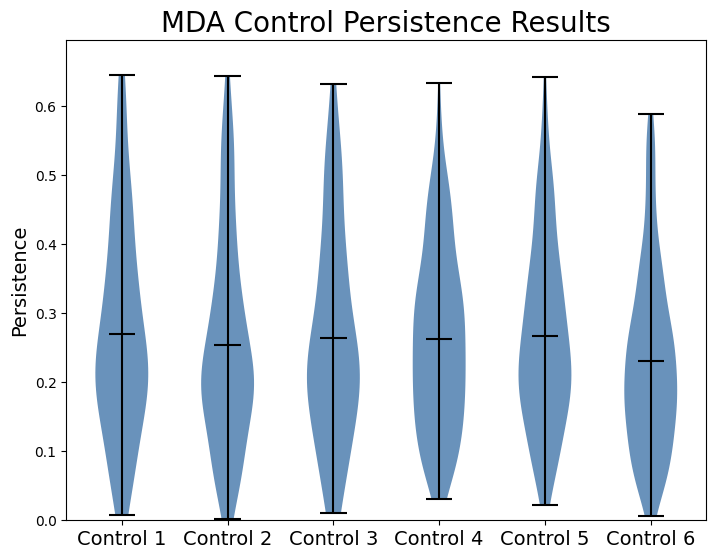

In [ ]:
# Violin plot of MDA control persistence
MDA_pers_controls = (control_persistence[0], control_persistence[1],
                     control_persistence[2], control_persistence[3],
                     control_persistence[4], control_persistence[5])
fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xticks([1, 2, 3, 4, 5, 6])
ax.set_xticklabels(['Control 1', 'Control 2', 'Control 3', 'Control 4', 'Control 5', 'Control 6'], fontsize=14)
ax.set_ylim([0, np.max(np.concatenate(MDA_pers_controls)) + 0.05])
plt.ylabel('Persistence', fontsize=14)
vp = ax.violinplot([control_persistence[0], control_persistence[1],
                    control_persistence[2], control_persistence[3],
                    control_persistence[4], control_persistence[5]],
                    showmeans=True, orientation='vertical')

vp['cbars'].set_color('black')
vp['cmeans'].set_color('black')
vp['cmaxes'].set_color('black')
vp['cmins'].set_color('black')

for i in range(6):
  vp['bodies'][i].set_facecolor((68/255.0, 119/255.0, 170/255.0))
  vp['bodies'][i].set_alpha(0.8)

plt.title('MDA Control Persistence Results', fontsize=20)

plt.show()

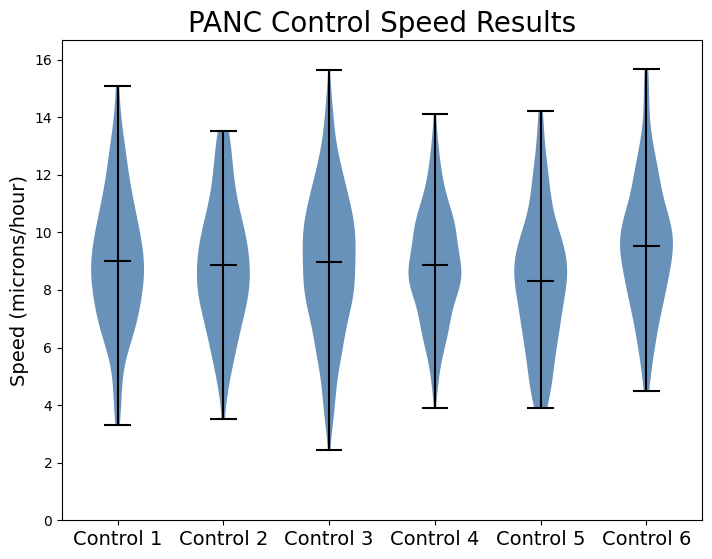

In [ ]:
# Violin plot of PANC control speeds
PANC_speed_controls = (control_speed[6], control_speed[7], control_speed[8],
                       control_speed[9], control_speed[10], control_speed[11])
fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xticks([1, 2, 3, 4, 5, 6])
ax.set_xticklabels(['Control 1', 'Control 2', 'Control 3', 'Control 4', 'Control 5', 'Control 6'], fontsize=14)
ax.set_ylim([0, np.max(np.concatenate(PANC_speed_controls)) + 1])
plt.ylabel('Speed (microns/hour)', fontsize=14)
vp = ax.violinplot([control_speed[6], control_speed[7], control_speed[8],
                    control_speed[9], control_speed[10], control_speed[11]],
                    showmeans=True, orientation='vertical')

vp['cbars'].set_color('black')
vp['cmeans'].set_color('black')
vp['cmaxes'].set_color('black')
vp['cmins'].set_color('black')

for i in range(6):
  vp['bodies'][i].set_facecolor((68/255.0, 119/255.0, 170/255.0))
  vp['bodies'][i].set_alpha(0.8)

plt.title('PANC Control Speed Results', fontsize=20)

plt.show()

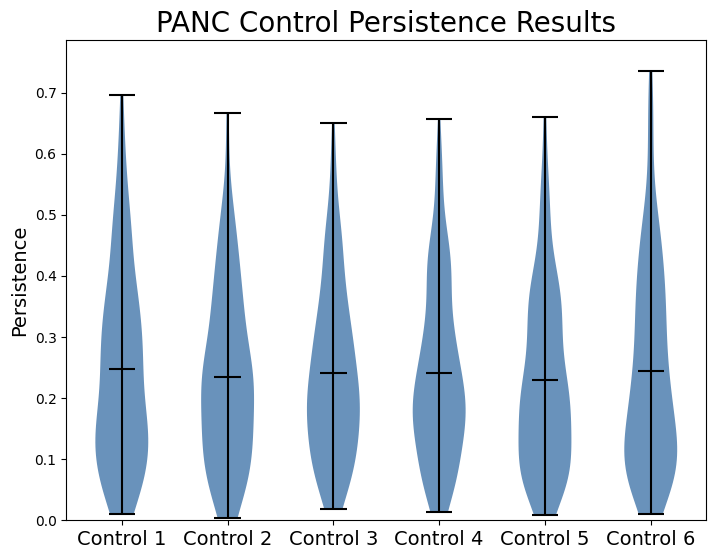

In [ ]:
# Violin plot of PANC control persistence
PANC_pers_controls = (control_persistence[6], control_persistence[7],
                      control_persistence[8], control_persistence[9],
                      control_persistence[10], control_persistence[11])
fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xticks([1, 2, 3, 4, 5, 6])
ax.set_xticklabels(['Control 1', 'Control 2', 'Control 3', 'Control 4', 'Control 5', 'Control 6'], fontsize=14)
ax.set_ylim([0, np.max(np.concatenate(PANC_pers_controls)) + 0.05])
plt.ylabel('Persistence', fontsize=14)
vp = ax.violinplot([control_persistence[6], control_persistence[7],
                    control_persistence[8], control_persistence[9],
                    control_persistence[10], control_persistence[11]],
                    showmeans=True, orientation='vertical')

vp['cbars'].set_color('black')
vp['cmeans'].set_color('black')
vp['cmaxes'].set_color('black')
vp['cmins'].set_color('black')

for i in range(6):
  vp['bodies'][i].set_facecolor((68/255.0, 119/255.0, 170/255.0))
  vp['bodies'][i].set_alpha(0.8)

plt.title('PANC Control Persistence Results', fontsize=20)

plt.show()

# MDA analysis

In [ ]:
# Averages
print("Averages:\n")
group_num = 1
for i in range(0, 4):
  avg_speed = np.mean(speed[i])
  avg_pers = np.mean(persistence[i])

  print(f'Group {group_num} average speed: {avg_speed}, average persistence: {avg_pers}\n')
  group_num += 1

# Pairwise ANOVAs for MDA groups
print('\nSpeed:\n')
for i in range(int(len(speed) / 2)):
  for j in range(i+1, int(len(speed) / 2)):
    speed_stat, speed_p = stats.f_oneway(speed[i], speed[j])
    print(f'(Group {i+1}, group {j+1}), Speed: {speed_stat}, {speed_p}\n')

print('\nPersistence:\n')
for i in range(int(len(persistence) / 2)):
  for j in range(i+1, int(len(persistence) / 2)):
    persistence_stat, persistence_p = stats.f_oneway(persistence[i], persistence[j])
    print(f'(Group {i+1}, group {j+1}), Persistence: {persistence_stat}, {persistence_p}\n')

Averages:

Group 1 average speed: 11.430083264376956, average persistence: 0.25558543936273254

Group 2 average speed: 9.301543221875656, average persistence: 0.22852283886481223

Group 3 average speed: 11.521395737596858, average persistence: 0.24600559694559687

Group 4 average speed: 10.15714740377531, average persistence: 0.2357294423854256


Speed:

(Group 1, group 2), Speed: 590.0477891171167, 1.6043086260605643e-117

(Group 1, group 3), Speed: 1.033704685253136, 0.30938098886821114

(Group 1, group 4), Speed: 268.47858311372664, 4.8097838562161284e-58

(Group 2, group 3), Speed: 540.8076161082972, 1.163429915678533e-108

(Group 2, group 4), Speed: 107.38325733443108, 9.255967589415498e-25

(Group 3, group 4), Speed: 267.0813328513409, 9.495379544138682e-58


Persistence:

(Group 1, group 2), Persistence: 25.547220752589464, 4.6204888578573123e-07

(Group 1, group 3), Persistence: 3.193157779713429, 0.07405943954614279

(Group 1, group 4), Persistence: 16.400408482505483, 5.24709

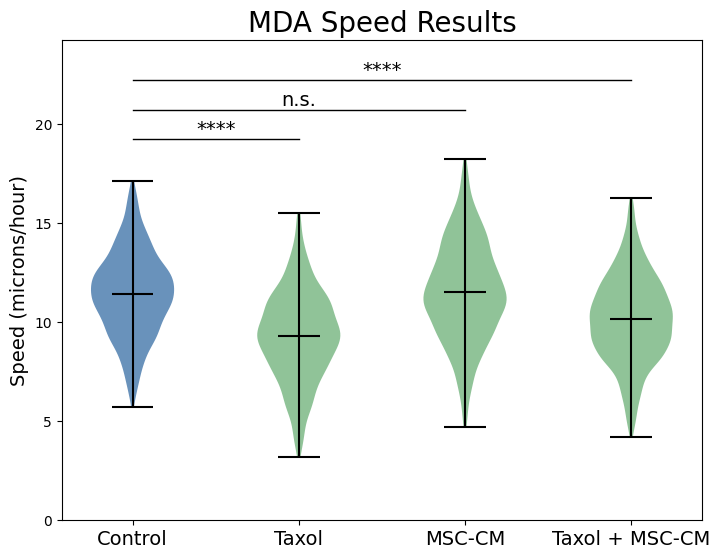

In [ ]:
# Violin plot of speed data for each MDA treatment group
MDA_speeds = (speed[0], speed[1], speed[2], speed[3])

fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(['Control', 'Taxol', 'MSC-CM', 'Taxol + MSC-CM'], fontsize=14)
ax.set_ylim([0, np.max(np.concatenate(MDA_speeds)) + 6])
plt.ylabel('Speed (microns/hour)', fontsize=14)
vp = ax.violinplot([speed[0], speed[1], speed[2], speed[3]],
                   showmeans=True, orientation='vertical')

vp['cbars'].set_color('black')
vp['cmeans'].set_color('black')
vp['cmaxes'].set_color('black')
vp['cmins'].set_color('black')

vp['bodies'][0].set_facecolor((68/255.0, 119/255.0, 170/255.0))
vp['bodies'][0].set_alpha(0.8)
for i in range(1, 4):
  vp['bodies'][i].set_facecolor((34/255.0, 136/255.0, 51/255.0))
  vp['bodies'][i].set_alpha(0.5)

plt.title('MDA Speed Results', fontsize=20)

pvals = []
for i in range(1, int(len(speed) / 2)):
  speed_stat, speed_p = stats.f_oneway(speed[0], speed[i])
  pvals.append(speed_p)

for i, pval in enumerate(pvals):
  h = np.max(np.concatenate(MDA_speeds) - 2)
  plt.plot([1, i+2], [h+(i+2)*1.5, h+(i+2)*1.5], '-k', lw=1)
  plt.text(1.5+i*0.5, h+(i+2)*1.5, asteriskscheck(pval), ha='center', va='bottom', fontsize=14)

plt.show()

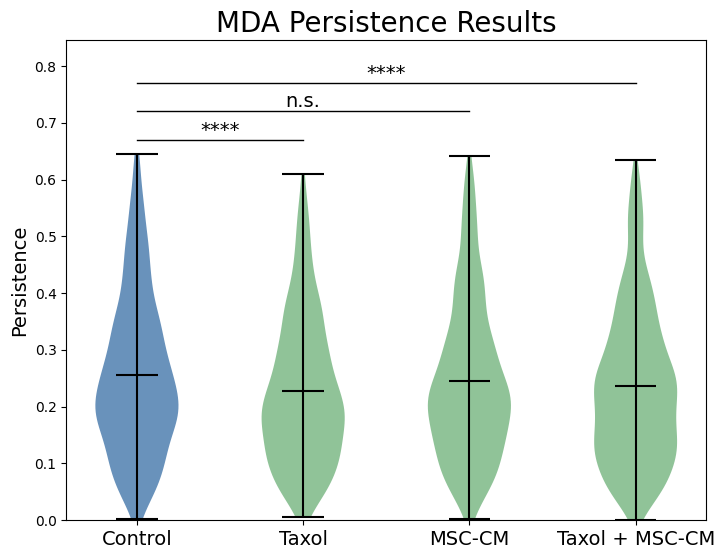

In [ ]:
# Violin plot of persistence data for each MDA treatment group
MDA_persistence = (persistence[0], persistence[1], persistence[2], persistence[3])

fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(['Control', 'Taxol', 'MSC-CM', 'Taxol + MSC-CM'], fontsize=14)
ax.set_ylim([0, np.max(np.concatenate(MDA_persistence))+0.2])
plt.ylabel('Persistence', fontsize=14)
vp = ax.violinplot([persistence[0], persistence[1], persistence[2], persistence[3]],
                   showmeans=True, orientation='vertical')

vp['cbars'].set_color('black')
vp['cmeans'].set_color('black')
vp['cmaxes'].set_color('black')
vp['cmins'].set_color('black')

vp['bodies'][0].set_facecolor((68/255.0, 119/255.0, 170/255.0))
vp['bodies'][0].set_alpha(0.8)
for i in range(1, 4):
  vp['bodies'][i].set_facecolor((34/255.0, 136/255.0, 51/255.0))
  vp['bodies'][i].set_alpha(0.5)

plt.title('MDA Persistence Results', fontsize=20)

pvals = []
for i in range(1, int(len(persistence) / 2)):
  pers_stat, pers_p = stats.f_oneway(persistence[0], persistence[i])
  pvals.append(pers_p)

for i, pval in enumerate(pvals):
  h = np.max(np.concatenate(MDA_persistence))
  plt.plot([1, i+2], [h+(i+0.5)*0.05, h+(i+0.5)*0.05], '-k', lw=1)
  plt.text(1.5+i*0.5, h+(i+0.5)*0.05, asteriskscheck(pval), ha='center', va='bottom', fontsize=14)

plt.show()

# PANC analysis

In [ ]:
# Averages
print("Averages:\n")
group_num = 5
for i in range(4, 8):
  avg_speed = np.mean(speed[i])
  avg_pers = np.mean(persistence[i])

  print(f'Group {group_num} average speed: {avg_speed}, average persistence: {avg_pers}\n')
  group_num += 1

# Pairwise ANOVAs for PANC groups
print('\nSpeed:\n')
for i in range(int(len(speed) / 2), len(speed)):
  for j in range(i+1, len(speed)):
    speed_stat, speed_p = stats.f_oneway(speed[i], speed[j])
    print(f'(Group {i+1}, group {j+1}), Speed: {speed_stat}, {speed_p}\n')

print('\nPersistence:\n')
for i in range(int(len(persistence) / 2), len(persistence)):
  for j in range(i+1, len(persistence)):
    persistence_stat, persistence_p = stats.f_oneway(persistence[i], persistence[j])
    print(f'(Group {i+1}, group {j+1}), Persistence: {persistence_stat}, {persistence_p}\n')

Averages:

Group 5 average speed: 8.912183945164397, average persistence: 0.23938194528656626

Group 6 average speed: 8.185463429374806, average persistence: 0.1829857509441572

Group 7 average speed: 9.203505495804974, average persistence: 0.2567493189252384

Group 8 average speed: 7.933151564029658, average persistence: 0.1885230855521901


Speed:

(Group 5, group 6), Speed: 64.65817867559252, 1.418838240684318e-15

(Group 5, group 7), Speed: 7.699186195856969, 0.005574122319066194

(Group 5, group 8), Speed: 97.69483533032685, 1.5394599384704872e-22

(Group 6, group 7), Speed: 96.4778716533126, 3.095790761578009e-22

(Group 6, group 8), Speed: 6.898607102954764, 0.008697671037678023

(Group 7, group 8), Speed: 125.97387336293865, 3.204432625116083e-28


Persistence:

(Group 5, group 6), Persistence: 94.21443539961646, 7.46807102028121e-22

(Group 5, group 7), Persistence: 5.982396510195057, 0.014531820694355482

(Group 5, group 8), Persistence: 64.49214884974148, 1.6195193150945521e

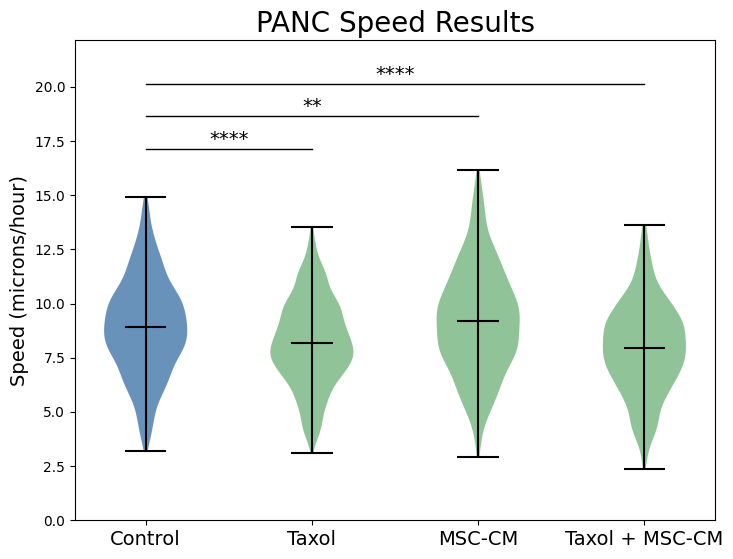

In [ ]:
# Violin plot of speed data for each PANC treatment group
PANC_speeds = (speed[4], speed[5], speed[6], speed[7])

fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(['Control', 'Taxol', 'MSC-CM', 'Taxol + MSC-CM'], fontsize=14)
ax.set_ylim([0, np.max(np.concatenate(PANC_speeds)) + 6])
plt.ylabel('Speed (microns/hour)', fontsize=14)
vp = ax.violinplot([speed[4], speed[5], speed[6], speed[7]], showmeans=True, orientation='vertical')

vp['cbars'].set_color('black')
vp['cmeans'].set_color('black')
vp['cmaxes'].set_color('black')
vp['cmins'].set_color('black')

vp['bodies'][0].set_facecolor((68/255.0, 119/255.0, 170/255.0))
vp['bodies'][0].set_alpha(0.8)
for i in range(1, 4):
  vp['bodies'][i].set_facecolor((34/255.0, 136/255.0, 51/255.0))
  vp['bodies'][i].set_alpha(0.5)

plt.title('PANC Speed Results', fontsize=20)

pvals = []
for i in range(int(len(speed) / 2) + 1, len(speed)):
  speed_stat, speed_p = stats.f_oneway(speed[4], speed[i])
  pvals.append(speed_p)

for i, pval in enumerate(pvals):
  h = np.max(np.concatenate(PANC_speeds) - 2)
  plt.plot([1, i+2], [h+(i+2)*1.5, h+(i+2)*1.5], '-k', lw=1)
  plt.text(1.5+i*0.5, h+(i+2)*1.5, asteriskscheck(pval), ha='center', va='bottom', fontsize=14)

plt.show()

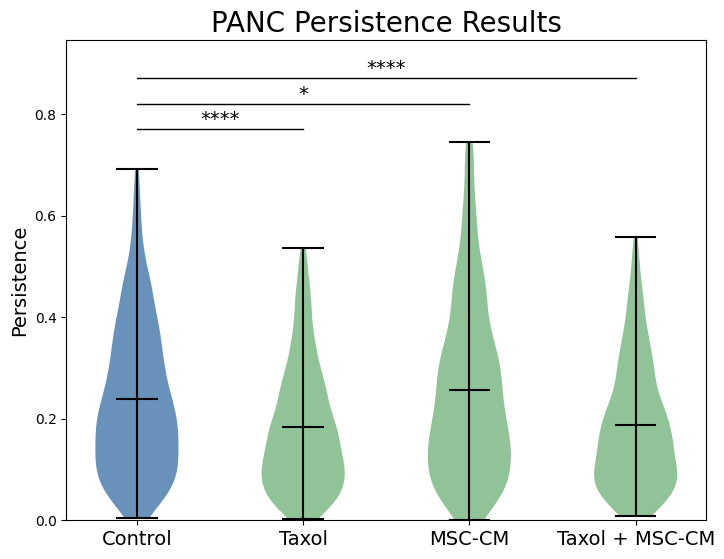

In [ ]:
# Violin plot of persistence data for each PANC treatment group
PANC_persistence = (persistence[4], persistence[5], persistence[6], persistence[7])

fig = plt.figure()
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(['Control', 'Taxol', 'MSC-CM', 'Taxol + MSC-CM'], fontsize=14)
ax.set_ylim([0, np.max(np.concatenate(PANC_persistence))+0.2])
plt.ylabel('Persistence', fontsize=14)
vp = ax.violinplot([persistence[4], persistence[5], persistence[6], persistence[7]],
                   showmeans=True, orientation='vertical')

vp['cbars'].set_color('black')
vp['cmeans'].set_color('black')
vp['cmaxes'].set_color('black')
vp['cmins'].set_color('black')

vp['bodies'][0].set_facecolor((68/255.0, 119/255.0, 170/255.0))
vp['bodies'][0].set_alpha(0.8)
for i in range(1, 4):
  vp['bodies'][i].set_facecolor((34/255.0, 136/255.0, 51/255.0))
  vp['bodies'][i].set_alpha(0.5)

plt.title('PANC Persistence Results', fontsize=20)

pvals = []
for i in range(int(len(persistence) / 2) + 1, int(len(persistence))):
  pers_stat, pers_p = stats.f_oneway(persistence[4], persistence[i])
  pvals.append(pers_p)

for i, pval in enumerate(pvals):
  h = np.max(np.concatenate(PANC_persistence))
  plt.plot([1, i+2], [h+(i+0.5)*0.05, h+(i+0.5)*0.05], '-k', lw=1)
  plt.text(1.5+i*0.5, h+(i+0.5)*0.05, asteriskscheck(pval), ha='center', va='bottom', fontsize=14)

plt.show()